# Recreating the UNR grid with GPS Imaging

The Nevada Geodetic Laboratory publishes gridded GPS for OPERA DISP calibration in two
products: a **time-constant** grid of MIDAS rates, and a **time-variable** grid of daily
positions. This notebook rebuilds both over Southern California from station positions,
with `geepers.gridding` and `geepers.gps_imaging`, and scores them against Version 0.3.

It follows the OPERA DISP-CAL ATBD, section 2.5, except where the published files show
otherwise. Those places are marked **inferred**, and collected at the end: they come from
reading the product, not from its authors.

To run another region, use the script, which does all of this for a box:

```bash
python scripts/recreate-unr-grid.py --bbox -118.5 33.8 -116.5 35.2 -o socal --workers 32
```

Running this notebook downloads about 800 station and grid files, roughly 0.5 GB. Set
`GEEPERS_UNR_CACHE` to keep them.

## How the two grids differ

Both grids start from the same station positions and use the same imaging. They differ in
what is imaged and in how the stations are prepared.

| | Time-constant grid | Time-variable grid |
|---|---|---|
| **Imaged value** | One filtered MIDAS rate per station | Each day's displacement since the first day |
| **Stations** | At least 4 years of record | At least 4 years since 2012 (**inferred**) |
| **Steps** | MIDAS pairs do not span catalogued steps | Equipment steps removed, earthquake steps kept |
| **Gaps** | Not a problem, MIDAS uses whatever pairs exist | Filled from neighbouring stations |
| **Weights** | SSF / velocity sigma | SSF alone (**inferred**) |
| **Result** | One rate per node, published as a straight line | One displacement per node per day |

Sections 1 to 3 are shared. Sections 4 and 5 build the time-constant grid, and sections 6
to 8 build the time-variable grid. Section 9 shows how the inferences were made, and
section 10 compares the two grids at one node. Sections 11 and 12 cover two options the steps above
do not use: breaklines and background models.

In [ ]:
%matplotlib inline
import multiprocessing as mp
import os
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from geepers import gridding
from geepers.gps_imaging import (
    crosses_breaklines,
    great_circle_degrees,
    linked_stations,
    make_ssf,
    msf_interpolate,
    tri_vertex_neighbors,
    weighted_medians,
)
from geepers.gps_sources import UnrGridSource, UnrSource
from geepers.midas import midas, select_pairs
from geepers.steps import remove_known_steps
from scipy.spatial import Delaunay

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.color": "#e4e3df",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True})
BLUE, ORANGE, AQUA, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e"

CACHE = Path(os.environ.get("GEEPERS_UNR_CACHE", "unr_cache"))
WORKERS = min(32, os.cpu_count() or 1)
COMPONENTS = ("east", "north", "up")
BOX = (-118.5, 33.8, -116.5, 35.2)  # west, south, east, north
BUFFER = 1.5  # stations this far outside still feed the edge nodes
START, END = pd.Timestamp("2012-01-01"), pd.Timestamp("2026-03-06")
DAYS = pd.date_range(START, END - pd.Timedelta(days=1), freq="D")

stations_source = UnrSource(cache_dir=CACHE / "stations")
constant_source = UnrGridSource(gridded_type="constant", cache_dir=CACHE / "grid_constant")
variable_source = UnrGridSource(gridded_type="variable", cache_dir=CACHE / "grid_variable")

## 1. Nodes and stations

The grid is about 25 km apart. Stations beyond the box are kept, because a node's
neighbours can lie outside it.

52 nodes, 724 stations, 4072 catalogued steps


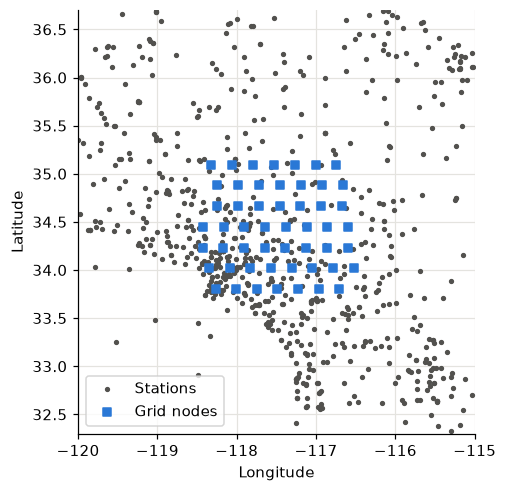

In [ ]:
nodes = pd.DataFrame(variable_source.stations(bbox=BOX))[["id", "lon", "lat"]].reset_index(drop=True)
west, south, east, north = BOX
outer = (west - BUFFER, south - BUFFER, east + BUFFER, north + BUFFER)
sites = pd.DataFrame(stations_source.stations(bbox=outer))[["id", "lon", "lat"]]
sites = sites.drop_duplicates("id").reset_index(drop=True)
steps = stations_source.steps(list(sites.id))
print(f"{len(nodes)} nodes, {len(sites)} stations, {len(steps)} catalogued steps")

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(sites.lon, sites.lat, s=6, color=MUTED, label="Stations")
ax.scatter(nodes.lon, nodes.lat, s=26, marker="s", color=BLUE, label="Grid nodes")
ax.set(xlim=outer[0::2], ylim=outer[1::2], aspect=1 / np.cos(np.radians(34.5)),
       xlabel="Longitude", ylabel="Latitude")
ax.legend(loc="lower left");

## 2. Station parameters

For each station: its MIDAS rate and uncertainty, its misfit to a trajectory model, a
variability index, and how long and complete its record is since 2012. The catalogued
steps keep MIDAS pairs from spanning them.

In [ ]:
def read_positions(site):
    try:
        df = stations_source.timeseries(site, frame="ENU", zero_by="none")
    except Exception:  # the station list includes sites with no series
        return None
    df = df.set_index(pd.DatetimeIndex(df["date"]).floor("D"))
    columns = [*COMPONENTS, *(f"sigma_{c}" for c in COMPONENTS)]
    df = df[columns] * 1000.0
    df = df[~df.index.duplicated()]
    return df[df.index < END]


step_dates = {s: pd.DatetimeIndex(g.date.unique()) for s, g in steps.groupby("id")}


def station_row(job):
    site, lon, lat = job
    df = read_positions(site)
    if df is None:
        return None
    row = gridding.station_parameters(df, step_dates.get(site, []), START)
    return None if row is None else {"id": site, "lon": lon, "lat": lat, **row}


jobs = [(s.id, s.lon, s.lat) for s in sites.itertuples()]
with ProcessPoolExecutor(WORKERS, mp_context=mp.get_context("fork")) as pool:
    rows = list(pool.map(station_row, jobs))
stats = pd.DataFrame([r for r in rows if r is not None])
print(f"{len(stats)} stations with at least 4 years")
stats[["id", "duration_since_start", "completeness", "ve", "se", "vu", "su", "misfit_u", "variability_u"]].head().round(2)

632 stations with at least 4 years


,id,duration_since_start,completeness,ve,se,vu,su,misfit_u,variability_u
0,7ODM,14.17,91.56,-27.40,0.18,0.09,0.53,4.58,1.94
1,ACSB,12.25,99.37,-38.85,0.14,-1.38,0.43,3.77,2.35
2,ACSX,9.87,99.25,-38.87,0.16,-1.30,0.50,3.71,2.40
3,AERO,10.89,38.55,-39.96,0.25,-1.09,0.79,3.44,2.13
4,AGMT,14.17,99.58,-18.72,0.12,0.24,0.32,3.95,2.09


### What MIDAS does

MIDAS ([Blewitt et al., 2016](https://doi.org/10.1002/2015JB012552)) is the source of every
station rate. It pairs each observation with one about a year later, so seasonal signal
mostly cancels, and it skips pairs that span a catalogued step. The slopes of those pairs
form a distribution. It takes the median, trims slopes more than 2 sigma from it, and takes
the median again.

CCCC shows why this matters. It moved in the 2019 Ridgecrest earthquakes, and a straight line
fit through that step is off by more than 4 mm/yr. Pairs spanning a step only widen the tails
of the distribution, so even keeping them moves the median by about 0.25 mm/yr. Passing the
step dates removes them.

12911 pairs avoid the steps, of 17469 without that rule
MIDAS by hand -20.909 mm/yr, geepers.midas -20.909 mm/yr
All pairs, median -21.158 mm/yr; straight line fit -25.280 mm/yr


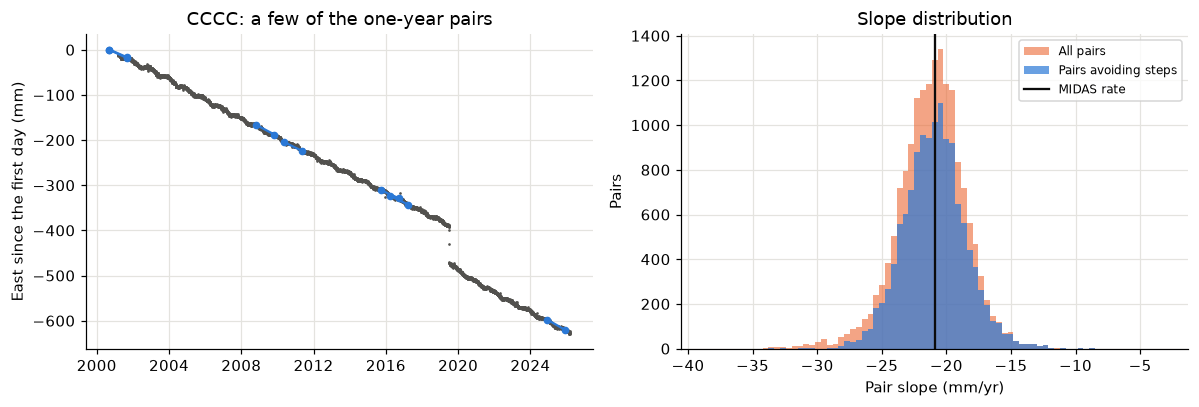

In [ ]:
site = "CCCC"
df = read_positions(site)
t = gridding.years_since(df.index, START)
y = df["east"].to_numpy() - df["east"].iloc[0]
station_steps = gridding.years_since(pd.DatetimeIndex(sorted(step_dates.get(site, []))), START)
station_steps = np.unique(station_steps[(station_steps > t[0]) & (station_steps < t[-1])])


def pair_slopes(t, y, step_times=None):
    # Forward and backward in time, as MIDAS does, so both ends of the record count
    backward_steps = None if step_times is None else -step_times[::-1]
    forward = select_pairs(t, 19999, 0.001, step_times)[1]
    backward = len(t) - 1 - select_pairs(-t[::-1], 19999, 0.001, backward_steps)[1][:, ::-1]
    pairs = np.vstack([forward, backward])
    return (y[pairs[:, 1]] - y[pairs[:, 0]]) / (t[pairs[:, 1]] - t[pairs[:, 0]]), pairs


slopes, pairs = pair_slopes(t, y, station_steps)
all_slopes, _ = pair_slopes(t, y)

first = np.median(slopes)
scatter = 1.4826 * np.median(np.abs(slopes - first))
by_hand = np.median(slopes[np.abs(slopes - first) < 2 * scatter])
fit = midas(t, y, station_steps)
line = np.polyfit(t, y, 1)[0]
print(f"{len(slopes)} pairs avoid the steps, of {len(all_slopes)} without that rule")
print(f"MIDAS by hand {by_hand:.3f} mm/yr, geepers.midas {fit.velocity:.3f} mm/yr")
print(f"All pairs, median {np.median(all_slopes):.3f} mm/yr; straight line fit {line:.3f} mm/yr")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.plot(df.index, y, ".", ms=1.5, color=MUTED)
for i, j in pairs[:: len(pairs) // 6]:
    ax.plot(df.index[[i, j]], y[[i, j]], "-o", ms=4, lw=1.5, color=BLUE)
ax.set(ylabel="East since the first day (mm)", title=f"{site}: a few of the one-year pairs")
ax = axes[1]
span = np.array([first - 8 * scatter, first + 8 * scatter])
bins = np.linspace(*span, 80)
ax.hist(all_slopes, bins=bins, color=ORANGE, alpha=0.6, label="All pairs")
ax.hist(slopes, bins=bins, color=BLUE, alpha=0.7, label="Pairs avoiding steps")
ax.axvline(fit.velocity, color=INK, lw=1.5, label="MIDAS rate")
ax.set(xlabel="Pair slope (mm/yr)", ylabel="Pairs", title="Slope distribution")
ax.legend(fontsize=8)
fig.tight_layout()

## 3. GPS Imaging: one node

Imaging ([Hammond, Blewitt and Kreemer, 2016](https://doi.org/10.1002/2016JB013458)) is a robust
interpolator. A point is added to the Delaunay triangulation of the stations, the stations
connected to it are its neighbours, and its value is their **weighted median**, so a single
bad station cannot pull it.

Weights come from a spatial structure function (SSF) of distance. The ATBD's Figure 2-23
lists one node's stations with their weights, and `gridding.atbd_ssf` is that curve. It is
much flatter than one estimated regionally with `make_ssf`, and it matches the product much
better.

station    km  weight
   VNPS  7.19    0.18
   P517  8.08    0.18
   CJVG  9.32    0.18
   P587 17.87    0.16
   QHTP 21.30    0.16
   CMP9 24.89    0.15


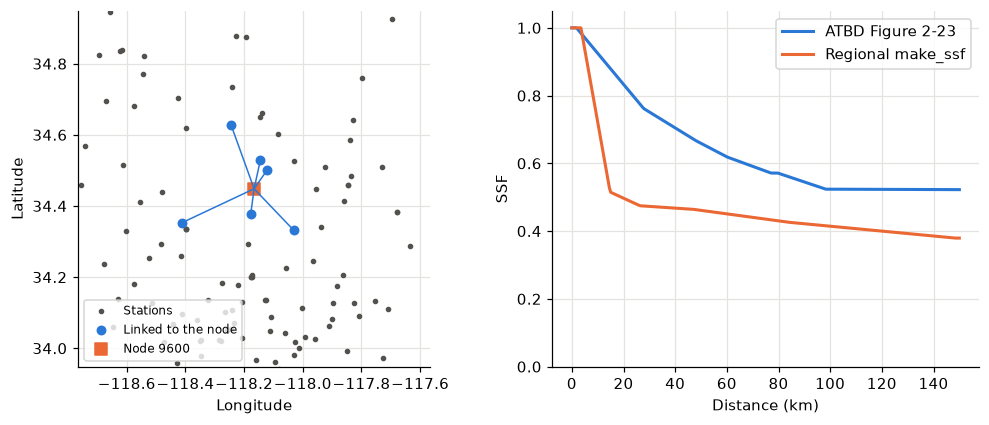

In [ ]:
ssf = gridding.atbd_ssf()
regional = make_ssf(stats.lon, stats.lat, stats.vu, stats.su)
km_per_degree = 111.195

node = nodes[nodes.id == 9600].iloc[0]
lon, lat = stats.lon.to_numpy(), stats.lat.to_numpy()
neighbors = tri_vertex_neighbors(Delaunay(np.c_[lon, lat]))
linked = linked_stations(lon, lat, node.lon, node.lat, neighbors)
km = great_circle_degrees(node.lat, node.lon, lat[linked], lon[linked]) * km_per_degree
weight = np.interp(km / km_per_degree, ssf[:, 0], ssf[:, 1])
print(pd.DataFrame({"station": stats.id.to_numpy()[linked], "km": km, "weight": weight / weight.sum()})
      .sort_values("km").round(2).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axes[0]
ax.scatter(lon, lat, s=7, color=MUTED, label="Stations")
for j in linked:
    ax.plot([node.lon, lon[j]], [node.lat, lat[j]], color=BLUE, lw=1)
ax.scatter(lon[linked], lat[linked], s=30, color=BLUE, label="Linked to the node")
ax.scatter(node.lon, node.lat, s=70, marker="s", color=ORANGE, label="Node 9600")
ax.set(xlim=(node.lon - 0.6, node.lon + 0.6), ylim=(node.lat - 0.5, node.lat + 0.5),
       aspect=1 / np.cos(np.radians(node.lat)), xlabel="Longitude", ylabel="Latitude")
ax.legend(loc="lower left", fontsize=8)
ax = axes[1]
d = np.linspace(0, 150, 300)
ax.plot(d, np.interp(d / km_per_degree, ssf[:, 0], ssf[:, 1]), color=BLUE, lw=2, label="ATBD Figure 2-23")
ax.plot(d, np.interp(d / km_per_degree, regional[:, 0], regional[:, 1]), color=ORANGE, lw=2, label="Regional make_ssf")
ax.set(xlabel="Distance (km)", ylabel="SSF", ylim=(0, 1.05))
ax.legend();

## 4. Filtering the rates

Each station's rate is replaced by the weighted median of its Delaunay neighbours, 30 times
with the SSF perturbed by up to 20%, and the median of those is kept. This removes outliers
and speckle. The difference from the original rate is also what the selection step calls
speckle.

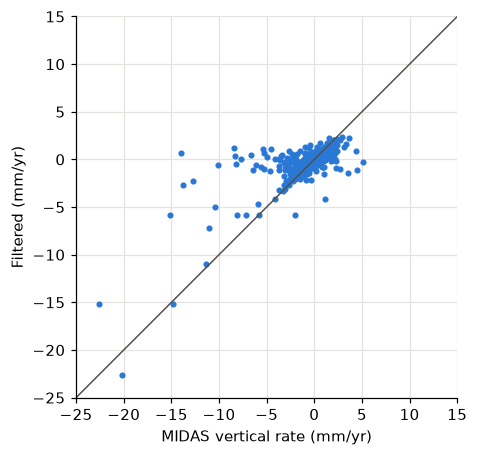

In [ ]:
stats = stats.join(gridding.filter_station_rates(stats, ssf))
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.scatter(stats.vu, stats.vmsfu, s=9, color=BLUE)
limits = np.array([-25, 15])
ax.plot(limits, limits, color=MUTED, lw=1)
ax.set(xlim=limits, ylim=limits, aspect=1, xlabel="MIDAS vertical rate (mm/yr)", ylabel="Filtered (mm/yr)");

The difference between a station's rate and its filtered rate is its speckle. Most stations
barely change. A large value says only that a station disagrees with its neighbours, not that
it is wrong: the cluster of large negative values in the northwest lies in the Central Valley,
where it may be real subsidence. Either way the filter takes that signal out of the rate that
gets imaged. The colours are clipped at 5 mm/yr.

count    632.00
mean       2.31
std       15.63
min        0.00
50%        0.33
90%        2.29
99%       29.57
max      279.21


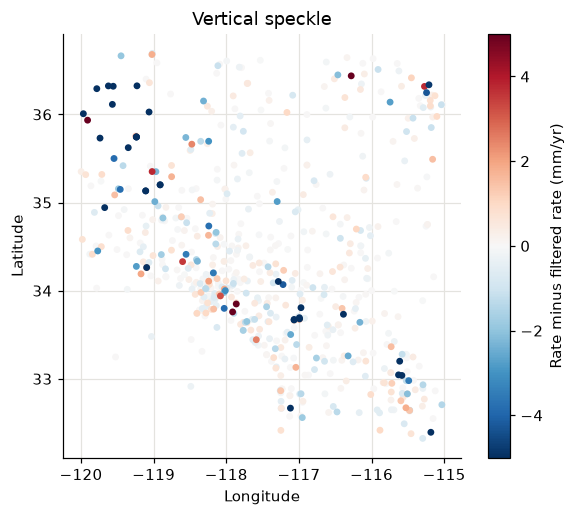

In [ ]:
speckle = stats.vu - stats.vmsfu
print(speckle.abs().describe(percentiles=[0.5, 0.9, 0.99]).round(2).to_string())
fig, ax = plt.subplots(figsize=(6.5, 5))
order = speckle.abs().sort_values().index
points = ax.scatter(stats.lon[order], stats.lat[order], c=speckle[order], s=12,
                    cmap="RdBu_r", vmin=-5, vmax=5)
ax.set(aspect=1 / np.cos(np.radians(34.5)), xlabel="Longitude", ylabel="Latitude",
       title="Vertical speckle")
fig.colorbar(points, ax=ax, label="Rate minus filtered rate (mm/yr)");

## 5. The time-constant grid

Stations are declustered, keeping the smallest vertical uncertainty within 10 m, and the
filtered rates are imaged onto the nodes. Here weights are SSF / velocity sigma, as Eq. (6)
says. The published files are exact straight lines, so their slopes are the published rates.

,component,rms_mm_yr,r
0,east,0.235,0.999
1,north,0.360,0.998
2,up,0.135,0.968


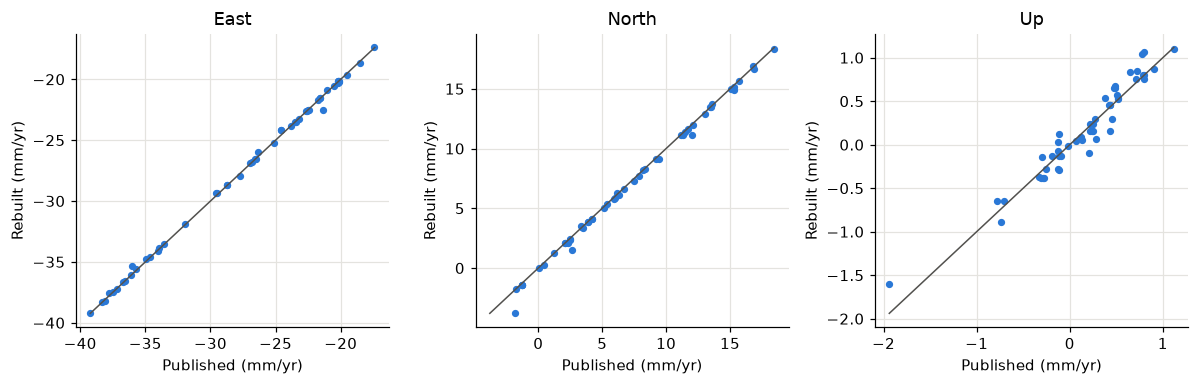

In [ ]:
rates = gridding.rate_grid(gridding.decluster(stats), nodes.lon, nodes.lat, ssf)
published_rates = pd.DataFrame(
    [
        {f"v{c[0]}": np.polyfit(df.decimal_year, df[c], 1)[0] for c in COMPONENTS}
        for df in map(constant_source.node_series, nodes.id)
    ]
)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
rows = []
for ax, c in zip(axes, COMPONENTS):
    key = f"v{c[0]}"
    ours, theirs = rates[key].to_numpy(), published_rates[key].to_numpy()
    span = np.array([min(ours.min(), theirs.min()), max(ours.max(), theirs.max())])
    ax.plot(span, span, color=MUTED, lw=1)
    ax.scatter(theirs, ours, s=14, color=BLUE)
    ax.set(xlabel="Published (mm/yr)", ylabel="Rebuilt (mm/yr)", title=c.capitalize())
    rows.append({"component": c, "rms_mm_yr": np.sqrt(np.mean((ours - theirs) ** 2)), "r": np.corrcoef(ours, theirs)[0, 1]})
fig.tight_layout()
pd.DataFrame(rows).round(3)

### One rate by hand

This repeats the imaging for one node. The node's linked stations are found in the
declustered network, each gets the weight SSF(distance) / sigma, and the node's rate is the
weighted median of their filtered rates. The result is one station's rate, not a blend. The
uncertainty is Eq. (11): the robust scatter of those stations and their median sigma, added
in quadrature and divided by the number of stations.

In [ ]:
network = gridding.decluster(stats)
net_lon, net_lat = network.lon.to_numpy(), network.lat.to_numpy()
net_neighbors = tri_vertex_neighbors(Delaunay(np.c_[net_lon, net_lat]))
index = nodes.index[nodes.id == 9600][0]
node = nodes.loc[index]
linked = linked_stations(net_lon, net_lat, node.lon, node.lat, net_neighbors)
degrees = great_circle_degrees(node.lat, node.lon, net_lat[linked], net_lon[linked])
distance_weight = np.interp(degrees, ssf[:, 0], ssf[:, 1])

table = pd.DataFrame({"station": network.id.to_numpy()[linked], "km": degrees * km_per_degree})
rows = []
for c in "enu":
    value = network[f"vmsf{c}"].to_numpy()[linked]
    sigma = network[f"s{c}"].to_numpy()[linked]
    weight = distance_weight / sigma
    hand = weighted_medians(value, weight)
    scatter = 1.4826 * np.median(np.abs((value - hand) - np.median(value - hand)))
    table[f"v{c}"], table[f"weight_{c}"] = value, weight / weight.sum()
    rows.append(
        {
            "component": c,
            "by hand (mm/yr)": hand,
            "rate_grid (mm/yr)": rates[f"v{c}"][index],
            "sigma by hand": np.sqrt((scatter**2 + np.median(sigma) ** 2) / len(linked)),
            "sigma rate_grid": rates[f"s{c}"][index],
        }
    )
print(table.sort_values("km").round(2).to_string(index=False))
pd.DataFrame(rows).round(4)

station    km     ve  weight_e    vn  weight_n    vu  weight_u
   VNPS  7.19 -31.60      0.19  9.89      0.21  0.25      0.19
   P517  8.08 -34.61      0.19 11.36      0.19  0.68      0.20
   CJVG  9.32 -31.60      0.12  9.89      0.12  0.53      0.12
   P587 17.87 -34.57      0.18 11.13      0.18  0.53      0.17
   QHTP 21.30 -31.00      0.15  9.84      0.14 -0.82      0.15
   CMP9 24.89 -36.17      0.17 12.50      0.16  0.54      0.17


,component,by hand (mm/yr),rate_grid (mm/yr),sigma by hand,sigma rate_grid
0,e,-34.5727,-34.5727,0.914,0.914
1,n,11.1296,11.1296,0.394,0.394
2,u,0.5261,0.5261,0.180,0.180


The published time-constant file for a node holds positions, not a rate. They lie on an exact
straight line, to the rounding of the file, so the slope is the rate.

In [ ]:
df = constant_source.node_series(9600)
for c in COMPONENTS:
    coefficients = np.polyfit(df.decimal_year, df[c], 1)
    departure = np.abs(df[c] - np.polyval(coefficients, df.decimal_year)).max()
    print(f"{c:>5}: slope {coefficients[0]:7.3f} mm/yr, largest departure from the line {departure:.4f} mm")

 east: slope -34.631 mm/yr, largest departure from the line 0.0005 mm
north: slope  11.186 mm/yr, largest departure from the line 0.0005 mm
   up: slope   0.514 mm/yr, largest departure from the line 0.0005 mm


## 6. Selecting stations for the daily grid

The ATBD asks for at least 7 years since 2012, 80% completeness, and limits on speckle,
misfit and variability.

**Inferred:** the product does not follow those limits. Published nodes follow stations they
reject, and keeping only the 4 year rule the ATBD gives for the time-constant product is closest
to the published grid in the regions tested. Near Kilauea, for example, published nodes follow
stations that fail the variability limit, and in the Aleutians the speckle limit removes the only
nearby stations. So `PUBLISHED_SELECTION` is used here.

In [ ]:
atbd = stats[gridding.select_time_variable(stats)]
chosen = gridding.decluster(stats[gridding.select_time_variable(stats, gridding.PUBLISHED_SELECTION)])
print(f"{len(stats)} stations, {len(atbd)} pass the ATBD rules, {len(chosen)} used here")

632 stations, 427 pass the ATBD rules, 575 used here


This is what each ATBD limit rejects, and where those stations are. A station can fail more
than one limit. The inferred rule keeps most of them, including ones the published nodes follow.

,Stations rejected
Under 4 years since 2012,51
Under 7 years since 2012,107
Under 80% complete,141
Speckle,14
Misfit,14
Variability,21


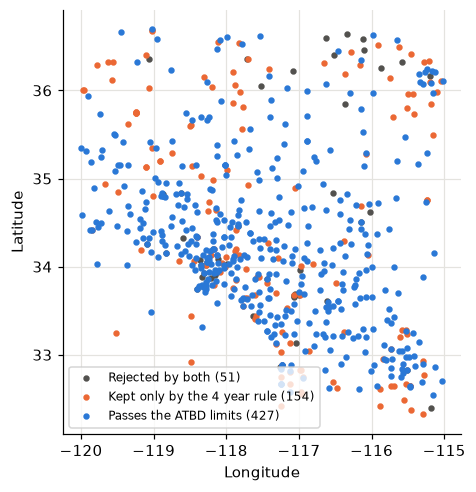

In [ ]:
limits = gridding.SelectionCriteria()


def fails(values, limit, strict=False):
    bad = [values(c) > limit[c] if strict else values(c) >= limit[c] for c in COMPONENTS]
    return pd.concat(bad, axis=1).any(axis=1)


reasons = {
    "Under 4 years since 2012": stats.duration_since_start < 4,
    "Under 7 years since 2012": stats.duration_since_start < limits.min_years,
    "Under 80% complete": stats.completeness < limits.min_completeness,
    "Speckle": fails(lambda c: (stats[f"v{c[0]}"] - stats[f"vmsf{c[0]}"]).abs(), limits.max_speckle),
    "Misfit": fails(lambda c: stats[f"misfit_{c[0]}"], limits.max_misfit, strict=True),
    "Variability": fails(lambda c: stats[f"variability_{c[0]}"], limits.max_variability),
}
display(pd.Series({k: int(v.sum()) for k, v in reasons.items()}, name="Stations rejected").to_frame())

passes_atbd = gridding.select_time_variable(stats)
passes_inferred = gridding.select_time_variable(stats, gridding.PUBLISHED_SELECTION)
fig, ax = plt.subplots(figsize=(6.5, 5))
groups = (
    (~passes_inferred, MUTED, "Rejected by both"),
    (passes_inferred & ~passes_atbd, ORANGE, "Kept only by the 4 year rule"),
    (passes_atbd, BLUE, "Passes the ATBD limits"),
)
for mask, color, label in groups:
    ax.scatter(stats.lon[mask], stats.lat[mask], s=10, color=color, label=f"{label} ({mask.sum()})")
ax.set(aspect=1 / np.cos(np.radians(34.5)), xlabel="Longitude", ylabel="Latitude")
ax.legend(loc="lower left", fontsize=8);

## 7. Filling the gaps

Every station needs a position every day. Equipment steps are removed from 30 days of data
either side. Earthquake steps are signal, and stay. Outliers become gaps. Each gap then
takes the weighted-median displacement of the stations around it since the nearest day with
data on either side, unless an earthquake intervenes. A second pass treats filled days as
data, and a trajectory model fills what is left.

In [ ]:
equipment = {s: pd.DatetimeIndex(g.date.unique()) for s, g in steps[steps.code == 1].groupby("id")}
quakes = {s: pd.DatetimeIndex(g.date.unique()) for s, g in steps[steps.code == 2].groupby("id")}
series = {s: read_positions(s) for s in chosen.id}
cube = gridding.build_position_cube(series, chosen, DAYS, equipment, quakes)
gappy = cube.x.copy()  # kept to redo a gap by hand below
available = sum(int((df.index >= START).sum()) for df in series.values())
print(f"{cube.x.shape[0]} stations, {cube.x.shape[1]} days")
print(f"{available} station days have a solution, {cube.observed.sum()} kept as data, "
      f"{cube.observed.mean():.0%} of the cube")

575 stations, 5178 days
2328557 station days have a solution, 2284442 kept as data, 77% of the cube


### Removing an equipment step

An equipment change moves a station's reported position without the ground moving, so it
has to go. Its size comes from the data within 30 days either side, stopping at any other
step. An earthquake step is ground motion, so it stays, and only limits that window. This
is the station whose vertical scatter about a straight line improves most, a clear case
rather than a typical one.
The short 2013 segment stays low, because no step is catalogued there.

424 of 575 stations have catalogued equipment steps
SIMM: correction 92.6 mm, vertical scatter down 4.3 times


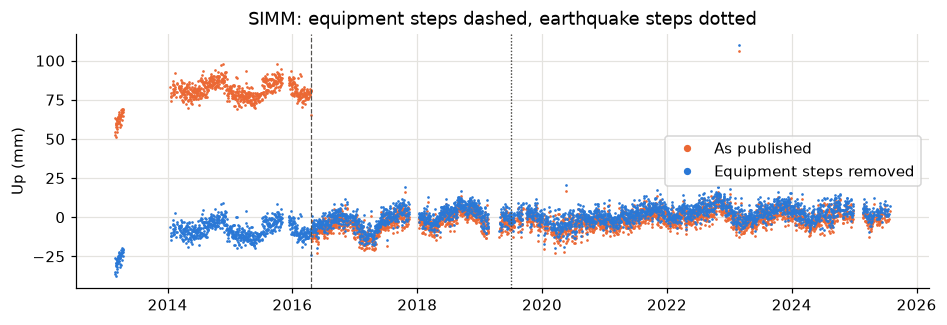

In [ ]:
def without_equipment(site):
    df = series[site]
    df = df[df.index >= START]
    t = gridding.years_since(df.index, START)
    def inside(dates):
        times = gridding.years_since(pd.DatetimeIndex(sorted(dates)), START)
        return np.unique(times[(times > t[0]) & (times < t[-1])])
    kit, eq = inside(equipment.get(site, [])), inside(quakes.get(site, []))
    return df, remove_known_steps(t, df["up"].to_numpy(), kit, other_steps=eq)


def scatter_about_line(t, y):
    return np.std(y - np.polyval(np.polyfit(t, y, 1), t))


improvement = {}
for site in chosen.id:
    if site in equipment:
        df, cleaned = without_equipment(site)
        if len(df) > 1 and np.ptp(df["up"].to_numpy() - cleaned) > 5:
            t = gridding.years_since(df.index, START)
            improvement[site] = scatter_about_line(t, df["up"].to_numpy()) / scatter_about_line(t, cleaned)
site = max(improvement, key=improvement.get)
df, cleaned = without_equipment(site)
print(f"{sum(s in equipment for s in chosen.id)} of {len(chosen)} stations have catalogued equipment steps")
print(f"{site}: correction {np.ptp(df['up'].to_numpy() - cleaned):.1f} mm, vertical scatter down {improvement[site]:.1f} times")

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(df.index, df["up"] - np.median(df["up"]), ".", ms=1.5, color=ORANGE, label="As published")
ax.plot(df.index, cleaned - np.median(cleaned), ".", ms=1.5, color=BLUE, label="Equipment steps removed")
for date in equipment[site]:
    if df.index[0] < date < df.index[-1]:
        ax.axvline(date, color=MUTED, lw=0.8, ls="--")
for date in quakes.get(site, []):
    if df.index[0] < date < df.index[-1]:
        ax.axvline(date, color=MUTED, lw=0.8, ls=":")
ax.set(ylabel="Up (mm)", title=f"{site}: equipment steps dashed, earthquake steps dotted")
ax.legend(markerscale=5);

### Filling every gap

Every station needs a value every day, so that the set of stations around a node never
changes. There are three stages. The first spatial pass uses only real data. The second
treats those filled days as data, which reaches gaps that had too few neighbours at first.
A trajectory model takes whatever is left.

In [ ]:
counts = gridding.fill_gaps(cube, ssf, n_workers=WORKERS)
total = sum(counts.values())
pd.DataFrame({"station days": counts, "share": {k: f"{v / total:.1%}" for k, v in counts.items()}})

,station days,share
observed,2284442,76.7%
spatial_pass_1,684865,23.0%
spatial_pass_2,5143,0.2%
model,2900,0.1%


### One gap by hand

Take a day missing from one station. The 45 nearest stations with data both on that day and
on a reference day are triangulated with the target, and the weighted median of the linked
stations' displacements between those two days is added to the target's position on the
reference day. The reference days are the nearest days with data before and after the gap,
giving two estimates, and the nearer reference counts more. A reference is not used if an
earthquake lies between it and the gap.

CAVI, 2012-06-12: gap of 27 days, 5 linked stations
Millimeters from the station's position on the day before the gap:


,from day before gap,from day after gap,by hand,fill_gaps
east,-0.397,0.613,0.089,0.089
north,2.575,1.367,1.993,1.993
up,0.001,3.078,1.483,1.483


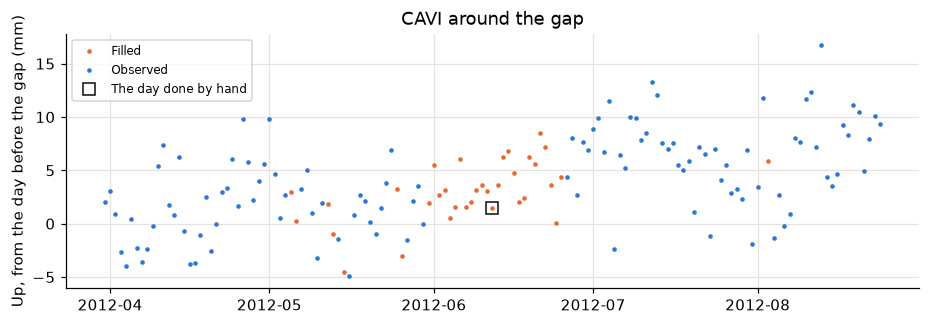

In [ ]:
have = np.isfinite(gappy[:, :, 0])
cube_lon, cube_lat = cube.lon, cube.lat


def find_gap():
    # A station close to 85% complete, with a 20 to 120 day gap and no earthquake across it
    for j in np.argsort(np.abs(cube.observed.mean(axis=1) - 0.85)):
        known = np.flatnonzero(have[j])
        for before, after in zip(known[:-1], known[1:]):
            size = after - before
            if 20 <= size <= 120 and not ((cube.earthquakes[j] > before) & (cube.earthquakes[j] <= after)).any():
                return j, int(before), int(after)
    raise ValueError("no suitable gap")


def estimate(j, day, ref):
    distance = great_circle_degrees(cube_lat[j], cube_lon[j], cube_lat, cube_lon)
    distance[j] = np.inf
    near = np.argsort(distance)[: gridding.N_NEIGHBORS]
    usable = near[have[near, day] & have[near, ref]]
    triangulation = Delaunay(np.c_[cube_lon[usable], cube_lat[usable]])
    linked = usable[linked_stations(cube_lon[usable], cube_lat[usable], cube_lon[j], cube_lat[j],
                                    tri_vertex_neighbors(triangulation))]
    weight = np.interp(great_circle_degrees(cube_lat[j], cube_lon[j], cube_lat[linked], cube_lon[linked]),
                       ssf[:, 0], ssf[:, 1])
    return gappy[j, ref] + weighted_medians(gappy[linked, day] - gappy[linked, ref], weight), linked


j, before, after = find_gap()
day = (before + after) // 2
from_before, _ = estimate(j, day, before)
from_after, linked = estimate(j, day, after)
share_before = (after - day) / (after - before)
hand = share_before * from_before + (1 - share_before) * from_after
origin = gappy[j, before]
print(f"{cube.sites[j]}, {DAYS[day].date()}: gap of {after - before} days, {linked.size} linked stations")
print("Millimeters from the station's position on the day before the gap:")
display(pd.DataFrame({"from day before gap": from_before - origin, "from day after gap": from_after - origin,
                      "by hand": hand - origin, "fill_gaps": cube.x[j, day] - origin}, index=COMPONENTS).round(3))

window = np.arange(max(before - 60, 0), min(after + 60, len(DAYS)))
fig, ax = plt.subplots(figsize=(10, 3))
is_data = cube.observed[j, window]
ax.plot(DAYS[window][~is_data], cube.x[j, window, 2][~is_data] - origin[2], ".", ms=4, color=ORANGE, label="Filled")
ax.plot(DAYS[window][is_data], cube.x[j, window, 2][is_data] - origin[2], ".", ms=4, color=BLUE, label="Observed")
ax.plot([DAYS[day]], [hand[2] - origin[2]], "s", ms=8, mfc="none", color=INK, label="The day done by hand")
ax.set(ylabel="Up, from the day before the gap (mm)", title=f"{cube.sites[j]} around the gap")
ax.legend(fontsize=8);

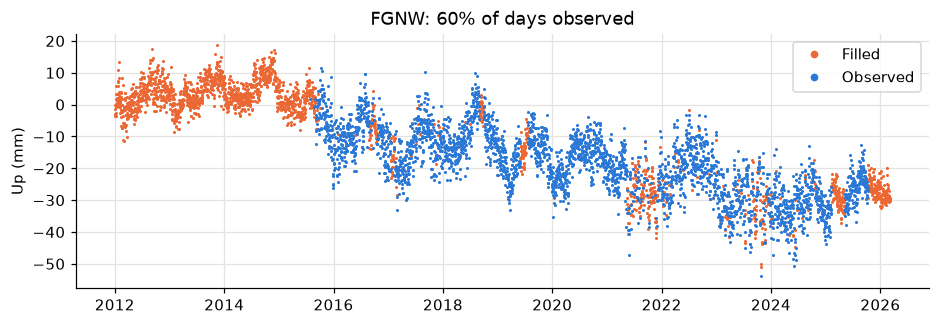

In [ ]:
share = cube.observed.mean(axis=1)
pick = int(np.argmin(np.abs(share - 0.6)))
fig, ax = plt.subplots(figsize=(10, 3))
y = cube.x[pick, :, 2] - cube.x[pick, 0, 2]
ax.plot(DAYS[~cube.observed[pick]], y[~cube.observed[pick]], ".", ms=2, color=ORANGE, label="Filled")
ax.plot(DAYS[cube.observed[pick]], y[cube.observed[pick]], ".", ms=2, color=BLUE, label="Observed")
ax.set(ylabel="Up (mm)", title=f"{cube.sites[pick]}: {share[pick]:.0%} of days observed")
ax.legend(markerscale=4);

## 8. Imaging each day

Displacement since the first day is imaged onto the nodes.

**Inferred:** the daily weights use distance alone, with no sigma. Replaying the published
medians with UNR's own station values, that picks the station UNR used far more often than
any rule with a daily, median or velocity sigma, or with temporal or spatial variability. In
the ATBD's own example IDML has extreme uncertainty and variability, yet its weight sits on
the distance curve. It is the default here, and `weight_by_sigma=True` gives Eq. (6) as written.

In [ ]:
images = gridding.image_positions(cube, nodes.lon, nodes.lat, ssf, n_workers=WORKERS)
with_sigma = gridding.image_positions(cube, nodes.lon, nodes.lat, ssf, n_workers=WORKERS, weight_by_sigma=True)
published = {int(n): variable_source.node_series(int(n)).reindex(DAYS) for n in nodes.id}


def monthly_rms(grid):
    rows = []
    for j, n in enumerate(nodes.id):
        for k, c in enumerate(COMPONENTS):
            error = grid[:, j, k] - published[int(n)][c].to_numpy()
            error = pd.Series(error - np.nanmedian(error), index=DAYS).resample("30D").median()
            rows.append({"id": int(n), "component": c, "rms": np.sqrt(np.nanmean(error**2)),
                         "sigma": published[int(n)][f"sigma_{c}"].median()})
    return pd.DataFrame(rows)


ours, sigma_rule = monthly_rms(images), monthly_rms(with_sigma)
pd.DataFrame(
    {
        "distance only (mm)": ours.groupby("component").rms.median(),
        "with daily sigma (mm)": sigma_rule.groupby("component").rms.median(),
        "published sigma (mm)": ours.groupby("component").sigma.median(),
    }
).loc[list(COMPONENTS)].round(2)

,distance only (mm),with daily sigma (mm),published sigma (mm)
component,,,
east,0.79,2.42,1.07
north,1.25,2.15,1.24
up,1.38,1.56,4.58


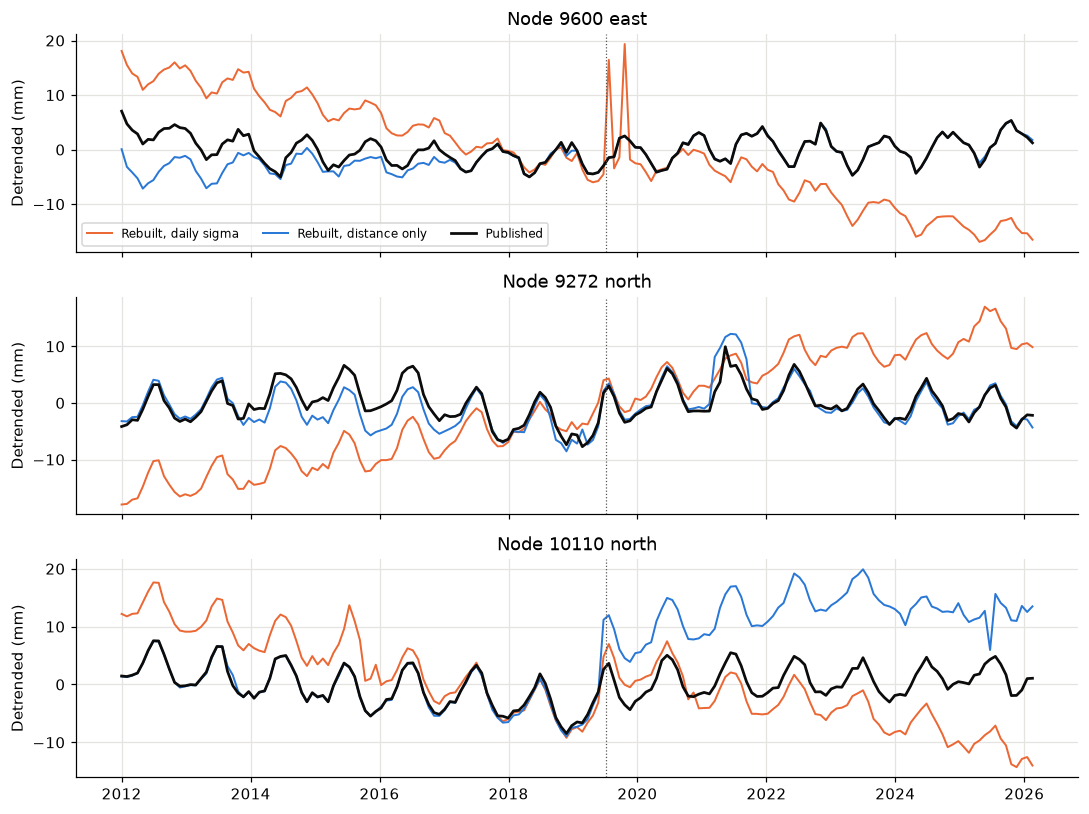

In [ ]:
monthly = lambda v: pd.Series(v, index=DAYS).resample("30D").median()
cases = ((9600, "east"), (9272, "north"), (10110, "north"))
ids = nodes.id.tolist()
fig, axes = plt.subplots(3, 1, figsize=(10, 7.5), sharex=True)
for ax, (n, c) in zip(axes, cases):
    theirs = published[n][c].to_numpy()
    good = np.isfinite(theirs)
    t = np.arange(len(DAYS))
    trend = np.polyval(np.polyfit(t[good], theirs[good], 1), t)
    k = COMPONENTS.index(c)
    for grid, color, label in ((with_sigma, ORANGE, "Rebuilt, daily sigma"), (images, BLUE, "Rebuilt, distance only")):
        y = grid[:, ids.index(n), k]
        ax.plot(monthly(y - np.nanmedian(y - theirs) - trend), color=color, lw=1.3, label=label)
    ax.plot(monthly(theirs - trend), color=INK, lw=1.8, label="Published")
    ax.axvline(pd.Timestamp("2019-07-05"), color=MUTED, lw=0.8, ls=":")
    ax.set(ylabel="Detrended (mm)", title=f"Node {n} {c}")
axes[0].legend(ncol=3, fontsize=8)
fig.tight_layout()

Most nodes now follow the published series. Node 10110 does not: the rebuild picks up a
large step at Ridgecrest in 2019 (dotted) that the product does not have. That is one of the
open problems below.

### One node through time

The neighbours and weights of a node are fixed for all days, because the filled cube has
every station every day and the weights use only distance. So the same weighted median is
applied to each day's displacements. The stations do not change, but which one is the median
can change from day to day, and the node's series then follows pieces of different stations.

Largest difference from image_positions: 0.000000 mm


,km,weight,share of days followed
VNPS,7.19,0.18,0.76
P517,8.08,0.18,0.01
CJVG,9.32,0.18,0.22
P587,17.87,0.16,0.00
QHTP,21.30,0.16,0.00
CMP9,24.89,0.15,0.00


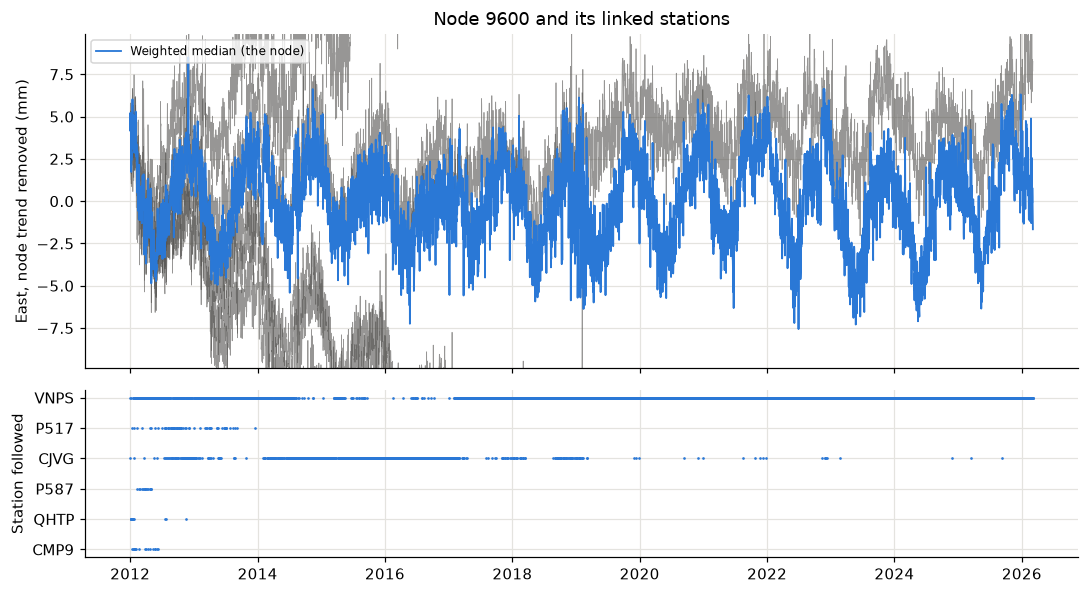

In [ ]:
ids = nodes.id.tolist()
index = ids.index(9600)
node = nodes.iloc[index]
cube_neighbors = tri_vertex_neighbors(Delaunay(np.c_[cube.lon, cube.lat]))
linked = linked_stations(cube.lon, cube.lat, node.lon, node.lat, cube_neighbors)
degrees = great_circle_degrees(node.lat, node.lon, cube.lat[linked], cube.lon[linked])
weight = np.interp(degrees, ssf[:, 0], ssf[:, 1])
order = np.argsort(degrees)
linked, degrees, weight = linked[order], degrees[order], weight[order]

displacement = cube.x[linked, :, 0] - cube.x[linked, :1, 0]
value = weighted_medians(displacement, weight)
print(f"Largest difference from image_positions: {np.abs(value - images[:, index, 0]).max():.6f} mm")
winner = np.abs(displacement - value).argmin(axis=0)
names = [cube.sites[i] for i in linked]
display(pd.DataFrame({"km": degrees * km_per_degree, "weight": weight / weight.sum(),
                      "share of days followed": np.bincount(winner, minlength=len(linked)) / len(DAYS)},
                     index=names).round(2))

t = np.arange(len(DAYS))
trend = np.polyval(np.polyfit(t, value, 1), t)
fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True, height_ratios=[2, 1])
ax = axes[0]
for row in displacement:
    ax.plot(DAYS, row - trend, lw=0.5, color=MUTED, alpha=0.6)
ax.plot(DAYS, value - trend, lw=1.2, color=BLUE, label="Weighted median (the node)")
limit = 4 * np.std(value - trend)
ax.set(ylabel="East, node trend removed (mm)", ylim=(-limit, limit), title="Node 9600 and its linked stations")
ax.legend(fontsize=8, loc="upper left")
ax = axes[1]
ax.plot(DAYS, winner, ".", ms=1.5, color=BLUE)
ax.set(yticks=range(len(names)), yticklabels=names, ylabel="Station followed")
ax.invert_yaxis()
fig.tight_layout()

## 9. How to see which station a node follows

A weighted median returns one station's value. So on days a node follows a station, node
minus station is a constant, to the rounding of the file. That is what makes the inferences
here possible: it needs no assumption about the recipe.

VNPS: the most common value of node minus station covers 4002 of 4897 days
P517: the most common value of node minus station covers 721 of 5144 days


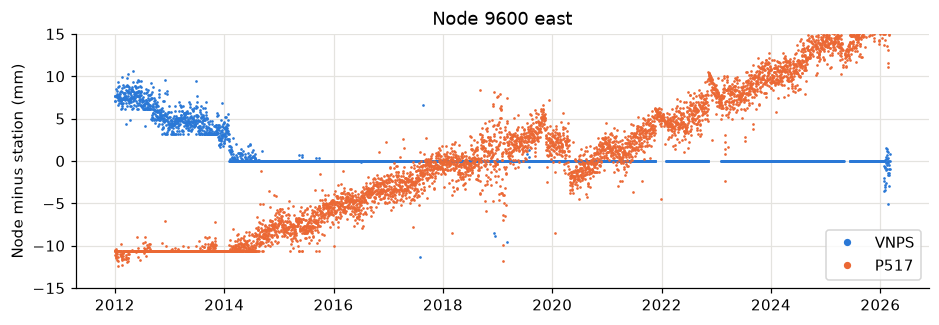

In [ ]:
theirs = published[9600]["east"]
fig, ax = plt.subplots(figsize=(10, 3))
for site, color in (("VNPS", BLUE), ("P517", ORANGE)):
    df = read_positions(site)
    df = df[df.index >= START]
    difference = (theirs.reindex(df.index) - df["east"]).round(2)
    difference = difference - difference.median()
    ax.plot(difference, ".", ms=1.5, color=color, label=site)
    value = difference.round(2).value_counts()
    print(f"{site}: the most common value of node minus station covers {value.iloc[0]} of {len(df)} days")
ax.set(ylabel="Node minus station (mm)", ylim=(-15, 15), title="Node 9600 east")
ax.legend(markerscale=5);

## 10. The two grids at one node

The time-constant grid is a single straight line. The time-variable grid carries what that
line leaves out, so the figure removes the published constant rate from the daily series, and
the constant grid itself is the zero line. They also come from different data: MIDAS rates use
each station's whole record, filtered, while the daily grid uses displacements since 2012 from
a different set of stations. So the slope of a daily series need not equal the node's constant
rate, and the table shows by how much, as the median over this region's nodes.

Node 9600 shows how far apart they can be. Its constant east rate is the median of the filtered
rates in section 5, which there is P587 at about -34.6 mm/yr, while its daily series mostly
follows VNPS, whose filtered rate is about -31.6 mm/yr. Their weights are similar, so the two
grids can settle on different stations. A difference of that size is consistent with the upward
trend in the east panel.

,component,"published, daily slope vs rate (mm/yr)","rebuilt, daily slope vs rate (mm/yr)"
0,east,0.528,0.484
1,north,0.906,0.767
2,up,0.309,0.296


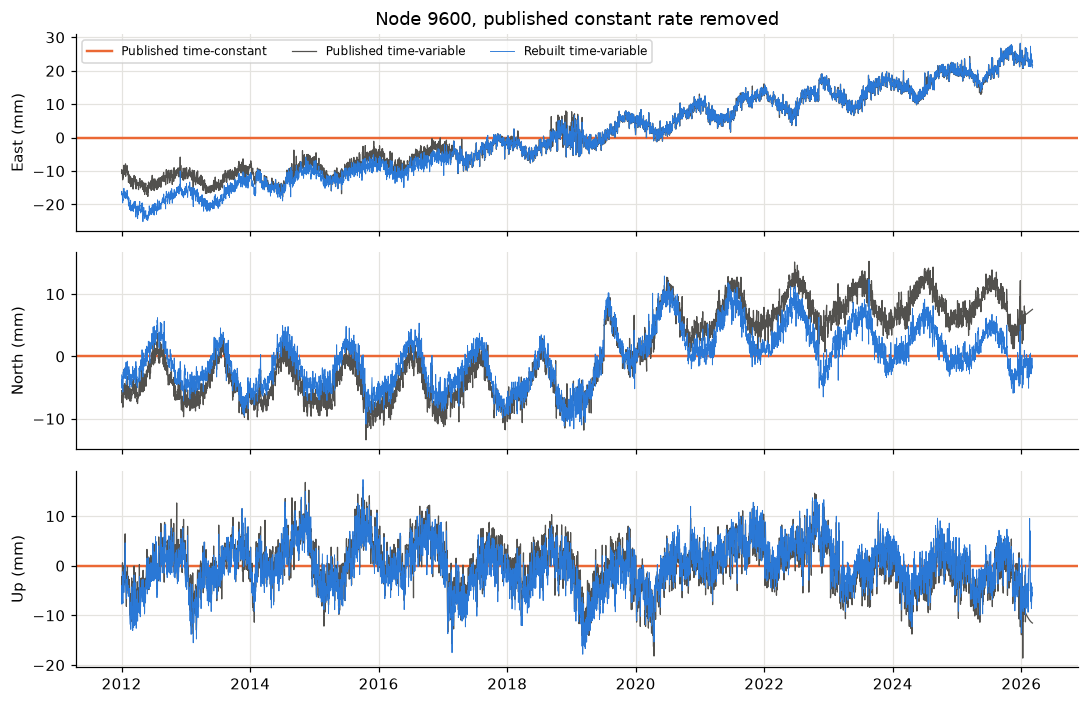

In [ ]:
index = ids.index(9600)
t = gridding.years_since(DAYS, START)
fig, axes = plt.subplots(3, 1, figsize=(10, 6.5), sharex=True)
for k, (ax, c) in enumerate(zip(axes, COMPONENTS)):
    line = published_rates[f"v{c[0]}"][index] * t
    theirs = published[9600][c].to_numpy()
    theirs = theirs - np.nanmedian(theirs - line)
    ours_daily = images[:, index, k] - np.nanmedian(images[:, index, k] - line)
    ax.axhline(0, color=ORANGE, lw=1.6, label="Published time-constant")
    ax.plot(DAYS, theirs - line, lw=0.8, color=MUTED, label="Published time-variable")
    ax.plot(DAYS, ours_daily - line, lw=0.6, color=BLUE, label="Rebuilt time-variable")
    ax.set(ylabel=f"{c.capitalize()} (mm)")
axes[0].set_title("Node 9600, published constant rate removed")
axes[0].legend(fontsize=8, ncol=3)
fig.tight_layout()

rows = []
for k, c in enumerate(COMPONENTS):
    published_daily = np.array([
        np.polyfit(t[np.isfinite(published[int(n)][c])],
                   published[int(n)][c].dropna().to_numpy(), 1)[0]
        for n in nodes.id
    ])
    rebuilt_daily = np.polyfit(t, images[:, :, k], 1)[0]
    rows.append(
        {
            "component": c,
            "published, daily slope vs rate (mm/yr)": np.median(np.abs(published_daily - published_rates[f"v{c[0]}"].to_numpy())),
            "rebuilt, daily slope vs rate (mm/yr)": np.median(np.abs(rebuilt_daily - rates[f"v{c[0]}"].to_numpy())),
        }
    )
pd.DataFrame(rows).round(3)

## 11. Option: breaklines

Imaging takes a node's motion from the stations linked to it. A link that crosses a real
discontinuity, such as a plate boundary, joins points that do not move together. A breakline is
a polyline marking such a place. The links crossing it stay, but `breakline_weight` scales down
their weight, 0.25 by default, so that most of the estimate comes from the point's own side. A
value of 0 drops those links and 1 ignores the breakline. If every link of a point crosses, the
stations on its own side join at full weight. The filter, the gap filling and the imaging all
accept `breaklines`.

Here the breaklines are the San Andreas traces in the
[GEM Global Active Faults](https://github.com/GEMScienceTools/gem-global-active-faults)
database. The node shown is the one whose east rate changes most at the default weight.

Node 9601: east -29.35 mm/yr without the breakline, -31.91 with it
By hand -31.9058 mm/yr, rate_grid -31.9058 mm/yr


,km,crosses,east rate (mm/yr),"weight, no breakline","weight, penalized"
P605,12.30,False,-33.47,0.17,0.29
JNHG,4.72,False,-31.91,0.12,0.21
DVPB,5.60,False,-31.46,0.16,0.27
HOL3,5.50,True,-29.35,0.18,0.07
PBPP,6.86,True,-28.97,0.19,0.08
LL01,7.55,True,-28.38,0.18,0.08


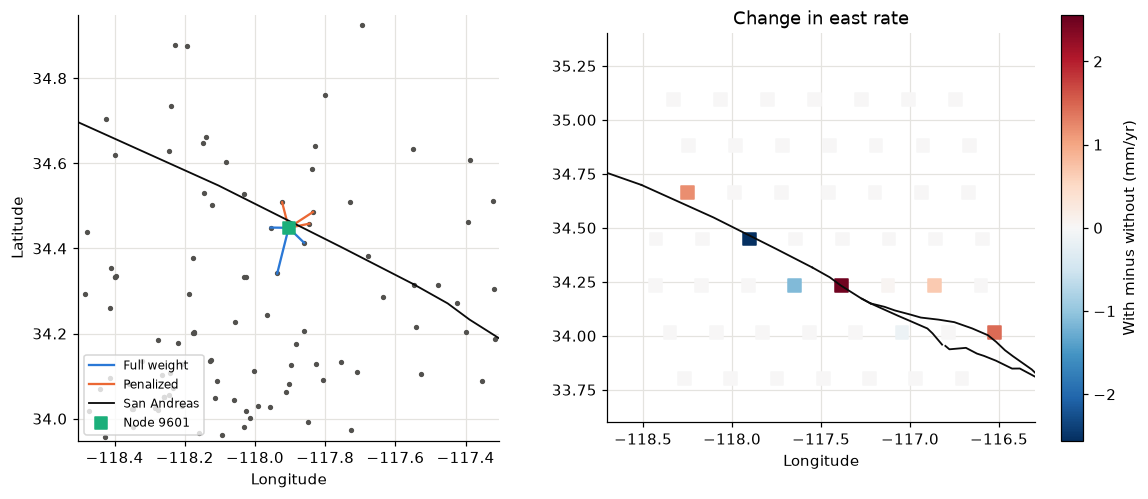

In [ ]:
fault_file = CACHE / "breaklines" / "gem_active_faults.geojson"
if not fault_file.exists():
    fault_file.parent.mkdir(parents=True, exist_ok=True)
    urlretrieve("https://raw.githubusercontent.com/GEMScienceTools/gem-global-active-faults/"
                "master/geojson/gem_active_faults_harmonized.geojson", fault_file)
faults = gridding.read_breaklines(fault_file, keep=lambda p: str(p.get("name") or "").startswith("San Andreas"))


def rebuild_rates(breakline_weight):
    filtered = stats.drop(columns=["vmsfe", "vmsfn", "vmsfu"])
    filtered = filtered.join(gridding.filter_station_rates(filtered, ssf, breaklines=faults, breakline_weight=breakline_weight))
    filtered = gridding.decluster(filtered)
    return filtered, gridding.rate_grid(filtered, nodes.lon, nodes.lat, ssf, breaklines=faults, breakline_weight=breakline_weight)


with_line, rates_line = rebuild_rates(gridding.DEFAULT_BREAKLINE_WEIGHT)
change = rates_line.ve - rates.ve
index = int(change.abs().to_numpy().argmax())
node = nodes.iloc[index]
node_id = int(node.id)
linked = linked_stations(net_lon, net_lat, node.lon, node.lat, net_neighbors)
crossing = crosses_breaklines(net_lon[linked], net_lat[linked], node.lon, node.lat, faults)
degrees = great_circle_degrees(node.lat, node.lon, net_lat[linked], net_lon[linked])
weight = np.interp(degrees, ssf[:, 0], ssf[:, 1]) / with_line.se.to_numpy()[linked]
scaled = weight * np.where(crossing, gridding.DEFAULT_BREAKLINE_WEIGHT, 1.0)
value = with_line.vmsfe.to_numpy()[linked]
print(f"Node {node_id}: east {rates.ve[index]:.2f} mm/yr without the breakline, {rates_line.ve[index]:.2f} with it")
print(f"By hand {weighted_medians(value, scaled):.4f} mm/yr, rate_grid {rates_line.ve[index]:.4f} mm/yr")
display(pd.DataFrame({"km": degrees * km_per_degree, "crosses": crossing, "east rate (mm/yr)": value,
                      "weight, no breakline": weight / weight.sum(), "weight, penalized": scaled / scaled.sum()},
                     index=network.id.to_numpy()[linked]).sort_values("east rate (mm/yr)").round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
ax = axes[0]
ax.scatter(net_lon, net_lat, s=6, color=MUTED)
for k, crosses in zip(linked, crossing):
    ax.plot([node.lon, net_lon[k]], [node.lat, net_lat[k]], color=ORANGE if crosses else BLUE, lw=1.5)
ax.plot([], [], color=BLUE, lw=1.5, label="Full weight")
ax.plot([], [], color=ORANGE, lw=1.5, label="Penalized")
for line in faults:
    ax.plot(line[:, 0], line[:, 1], color=INK, lw=1.2)
ax.plot([], [], color=INK, lw=1.2, label="San Andreas")
ax.scatter(node.lon, node.lat, s=70, marker="s", color=AQUA, zorder=3, label=f"Node {node_id}")
ax.set(xlim=(node.lon - 0.6, node.lon + 0.6), ylim=(node.lat - 0.5, node.lat + 0.5),
       aspect=1 / np.cos(np.radians(node.lat)), xlabel="Longitude", ylabel="Latitude")
ax.legend(loc="lower left", fontsize=8)
ax = axes[1]
for line in faults:
    ax.plot(line[:, 0], line[:, 1], color=INK, lw=1.2)
limit = change.abs().max()
points = ax.scatter(nodes.lon, nodes.lat, c=change, s=70, marker="s", cmap="RdBu_r", vmin=-limit, vmax=limit)
ax.set(xlim=(BOX[0] - 0.2, BOX[2] + 0.2), ylim=(BOX[1] - 0.2, BOX[3] + 0.2),
       aspect=1 / np.cos(np.radians(34.5)), xlabel="Longitude", title="Change in east rate")
fig.colorbar(points, ax=ax, label="With minus without (mm/yr)")
fig.tight_layout()

In [ ]:
# The cube was filled without the breakline, so only the imaging changes here
daily_scores = {"no breakline": monthly_rms(images)}
for label, w in (("0.25", 0.25), ("dropped", 0.0)):
    daily_scores[label] = monthly_rms(
        gridding.image_positions(cube, nodes.lon, nodes.lat, ssf, n_workers=WORKERS, breaklines=faults, breakline_weight=w)
    )
pd.concat(
    {label: frame.groupby("component").rms.agg(median="median", p90=lambda x: x.quantile(0.9))
     for label, frame in daily_scores.items()},
    axis=1,
).loc[list(COMPONENTS)].round(2)

no breakline         0.25       dropped      
                median   p90 median   p90  median   p90
component                                              
east              0.79  2.64   0.92  5.24    1.00  5.39
north             1.25  2.35   1.25  2.82    1.25  4.02
up                1.38  3.00   1.36  3.15    1.40  3.37

Agreement with the published grid only says what UNR did. A test that does not depend on UNR's
grid is to hold out each station in turn and predict its raw rate from the others. This repeats
that at each weight, with the median-based spread of the errors for stations within 30 km of
the fault and farther away, alongside the RMS against the published rates.

65 stations within 30 km of the fault, 106 farther away (mm/yr)


,held out near e,held out far e,published e,held out near n,held out far n,published n
breakline_weight,,,,,,
0.00,1.64,0.62,0.82,0.85,0.57,0.73
0.10,1.53,0.62,0.78,0.85,0.57,0.73
0.25,1.28,0.63,0.64,0.85,0.57,0.65
0.50,0.98,0.63,0.46,0.78,0.57,0.55
0.75,0.94,0.63,0.41,0.71,0.57,0.51
1.00,0.87,0.63,0.23,0.71,0.57,0.36


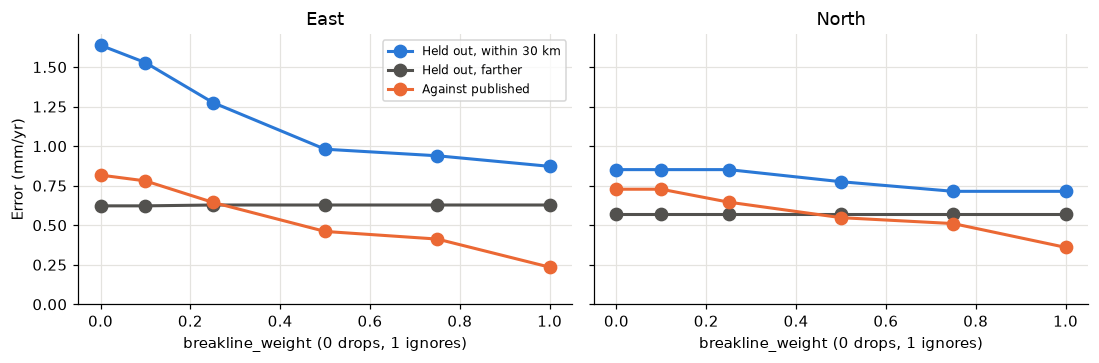

In [ ]:
held = network.reset_index(drop=True)
vertices = np.concatenate([np.concatenate([np.linspace(a, b, 20) for a, b in zip(line[:-1], line[1:])]) for line in faults])
km_to_fault = np.array([great_circle_degrees(la, lo, vertices[:, 1], vertices[:, 0]).min() * km_per_degree
                        for lo, la in zip(held.lon, held.lat)])
trial_weights = (0.0, 0.1, 0.25, 0.5, 0.75, 1.0)


def hold_out(i):
    rest = held.drop(index=i)
    row = {"km": km_to_fault[i]}
    for c in "en":
        for w in trial_weights:
            predicted = msf_interpolate(rest.lon, rest.lat, rest[f"v{c}"], rest[f"s{c}"], [held.lon[i]], [held.lat[i]],
                                        ssf, breaklines=faults, breakline_weight=w)
            row[f"{c}_{w}"] = predicted["value"].iloc[0] - held[f"v{c}"][i]
    return row


inside = held.index[held.lon.between(BOX[0], BOX[2]) & held.lat.between(BOX[1], BOX[3])]
with ProcessPoolExecutor(WORKERS, mp_context=mp.get_context("fork")) as pool:
    errors = pd.DataFrame(list(pool.map(hold_out, inside, chunksize=4)))

robust = lambda x: 1.4826 * x.abs().median()
near_fault, far_from_fault = errors[errors.km <= 30], errors[errors.km > 30]
rows = []
for w in trial_weights:
    grid = rebuild_rates(w)[1]
    row = {"breakline_weight": w}
    for c in "en":
        row[f"held out near {c}"] = robust(near_fault[f"{c}_{w}"])
        row[f"held out far {c}"] = robust(far_from_fault[f"{c}_{w}"])
        row[f"published {c}"] = np.sqrt(np.mean((grid[f"v{c}"] - published_rates[f"v{c}"]) ** 2))
    rows.append(row)
sweep = pd.DataFrame(rows).set_index("breakline_weight")
print(f"{len(near_fault)} stations within 30 km of the fault, {len(far_from_fault)} farther away (mm/yr)")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, c, title in zip(axes, "en", ("East", "North")):
    ax.plot(sweep.index, sweep[f"held out near {c}"], "-o", lw=2, ms=8, color=BLUE, label="Held out, within 30 km")
    ax.plot(sweep.index, sweep[f"held out far {c}"], "-o", lw=2, ms=8, color=MUTED, label="Held out, farther")
    ax.plot(sweep.index, sweep[f"published {c}"], "-o", lw=2, ms=8, color=ORANGE, label="Against published")
    ax.set(xlabel="breakline_weight (0 drops, 1 ignores)", title=title, ylim=(0, None))
axes[0].set_ylabel("Error (mm/yr)")
axes[0].legend(fontsize=8)
fig.tight_layout()
sweep.round(2)

**Result.** The penalty does less harm than dropping links, but on the San Andreas no weight beats
having no breakline. Held-out east error within 30 km falls from 1.64 mm/yr with dropped links to
1.28 at 0.25, and 0.87 with no breakline. Farther from the fault nothing changes. That fits the
ATBD's point that interseismic motion changes smoothly across a locked fault, so stations on both
sides carry useful information. So sections 1 to 10 do not use a fault breakline here.

A boundary with a true velocity step behaves differently. In a separate test beside the Gulf of
California, mainland-side rates against the published grid, east / north, were 3.67 / 2.71 mm/yr with
no breakline, 0.46 / 0.55 with dropped links and 0.45 / 0.46 at 0.25. That is why 0.25 is the default:
it matched or beat dropped links in both places. These are only two cases, the Gulf score relies on
UNR's grid, and the best value elsewhere may differ.

## 12. Option: background models

Where stations are sparse, the median of a few distant stations is a poor estimate, so the ATBD
adds one more value to the rate median: a background rate. Its weight depends on station density,
through the median distance to the ten nearest stations: zero within 100 km, one beyond 500 km,
and linear in log density between. Station weights are scaled to sum to one minus that weight.

The background itself comes from `local_plate_velocity`, a robust fit of rotation and uniform
strain to the station rates within 333 km, which needs at least 6 stations. It has east and north
only: there is no vertical tectonic background, and the ATBD's GIA model is not in geepers. The
rate grid accepts it, while `image_positions` has no background option. Every node here has zero
weight, because this network is dense, so the option changes nothing in this box. To see it work,
this thins the network at random.

Largest background weight at any node with the full network: 0.00


node trials  median weight  stations only (mm/yr)  \
stations component                                                      
12       e               1316.0           0.20                   3.97   
         n               1316.0           0.20                   3.66   
20       e                773.0           0.10                   3.98   
         n                773.0           0.10                   3.47   
40       e                137.0           0.06                   1.47   
         n                137.0           0.06                   1.82   

                    with background (mm/yr)  change, low  change, high  
stations component                                                      
12       e                             3.23        -0.76         -0.03  
         n                             2.40        -1.32         -0.64  
20       e                             4.01        -0.54          0.06  
         n                             2.73        -1.03         -0.24  
40       e                             1.49         0.00          0.00  
         n                             1.57        -0.28          0.00

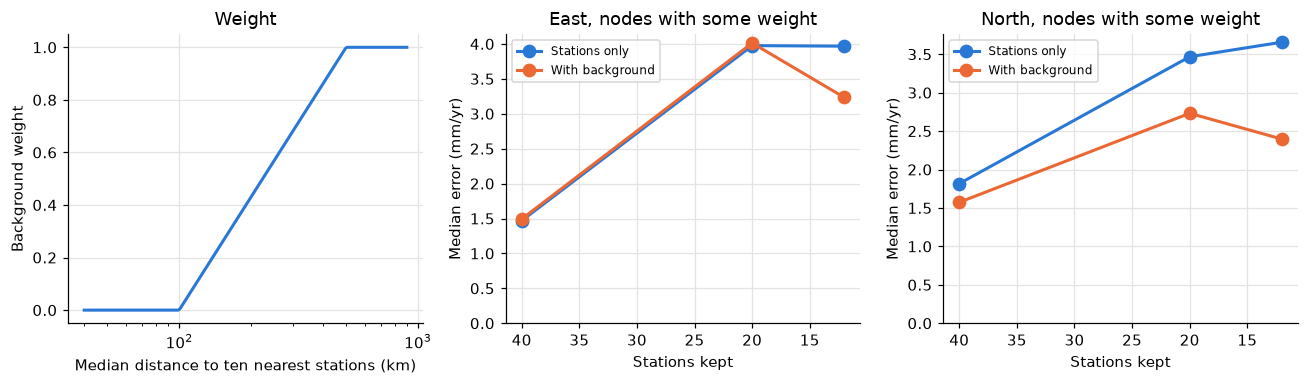

In [ ]:
km_range = np.geomspace(40, 900, 200)
curve = [gridding.background_weight(np.zeros(10), np.full(10, d / km_per_degree), [0.0], [0.0])[0] for d in km_range]
full_weight = gridding.background_weight(network.lon, network.lat, nodes.lon, nodes.lat)
print(f"Largest background weight at any node with the full network: {full_weight.max():.2f}")

rng = np.random.default_rng(0)
sizes = (40, 20, 12)
errors_by_node = []
examples = {}
for size in sizes:
    for trial in range(30):
        thin = network.iloc[np.sort(rng.choice(len(network), size, replace=False))].drop(columns=["vmsfe", "vmsfn", "vmsfu"])
        thin = thin.join(gridding.filter_station_rates(thin, ssf)).reset_index(drop=True)
        weight = gridding.background_weight(thin.lon, thin.lat, nodes.lon, nodes.lat)
        model = gridding.background_rates(thin, nodes.lon, nodes.lat)
        alone = gridding.rate_grid(thin, nodes.lon, nodes.lat, ssf)
        blended = gridding.rate_grid(thin, nodes.lon, nodes.lat, ssf, background=model, weight=weight)
        examples[size, trial] = (thin, weight, model, blended)
        for c in "en":
            errors_by_node.append(
                pd.DataFrame(
                    {
                        "stations": size, "trial": trial, "component": c, "weight": weight,
                        "alone": np.abs(alone[f"v{c}"] - rates[f"v{c}"]),
                        "blended": np.abs(blended[f"v{c}"] - rates[f"v{c}"]),
                        "has_model": np.isfinite(model[f"v{c}"]),
                    }
                )
            )
errors_by_node = pd.concat(errors_by_node, ignore_index=True)
# Only nodes where the background can act. The full-network rebuild is the reference.
active = errors_by_node[(errors_by_node.weight > 0) & errors_by_node.has_model].dropna(subset=["alone", "blended"])


def difference_interval(group, draws=2000):
    # Resample whole trials, since nodes within a trial share their stations
    by_trial = group.groupby("trial")[["alone", "blended"]].median()
    change = (by_trial.blended - by_trial.alone).to_numpy()
    picks = np.random.default_rng(1).integers(0, len(change), (draws, len(change)))
    low, high = np.percentile(np.median(change[picks], axis=1), [2.5, 97.5])
    return pd.Series({"node trials": len(group), "median weight": group.weight.median(),
                      "stations only (mm/yr)": group.alone.median(), "with background (mm/yr)": group.blended.median(),
                      "change, low": low, "change, high": high})


summary = active.groupby(["stations", "component"])[list(active.columns)].apply(difference_interval)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
ax = axes[0]
ax.plot(km_range, curve, lw=2, color=BLUE)
ax.set(xscale="log", xlabel="Median distance to ten nearest stations (km)", ylabel="Background weight", title="Weight")
for ax, c, title in zip(axes[1:], "en", ("East", "North")):
    part = summary.xs(c, level="component")
    ax.plot(part.index, part["stations only (mm/yr)"], "-o", lw=2, ms=8, color=BLUE, label="Stations only")
    ax.plot(part.index, part["with background (mm/yr)"], "-o", lw=2, ms=8, color=ORANGE, label="With background")
    ax.set(xlabel="Stations kept", ylabel="Median error (mm/yr)", title=f"{title}, nodes with some weight", ylim=(0, None))
    ax.invert_xaxis()
    ax.legend(fontsize=8)
fig.tight_layout()
summary.round(2)

### One background rate by hand

This is the node with the largest weight in the 12 station trials, in the east component.
The background is one more value in the same weighted median, so the result is either one
station's rate or the background itself.

In [ ]:
thin, weight, model, blended = max((examples[12, k] for k in range(30)), key=lambda e: np.max(np.where(np.isfinite(e[2].ve), e[1], 0)))
index = int(np.argmax(np.where(np.isfinite(model.ve), weight, 0)))
node = nodes.iloc[index]
thin_lon, thin_lat = thin.lon.to_numpy(), thin.lat.to_numpy()
linked = linked_stations(thin_lon, thin_lat, node.lon, node.lat, tri_vertex_neighbors(Delaunay(np.c_[thin_lon, thin_lat])))
degrees = great_circle_degrees(node.lat, node.lon, thin_lat[linked], thin_lon[linked])
station_weight = np.interp(degrees, ssf[:, 0], ssf[:, 1]) / thin.se.to_numpy()[linked]
station_weight = station_weight / station_weight.sum() * (1 - weight[index])
values = np.r_[thin.vmsfe.to_numpy()[linked], model.ve[index]]
all_weights = np.r_[station_weight, weight[index]]
display(pd.DataFrame({"km": np.r_[degrees * km_per_degree, np.nan], "east rate (mm/yr)": values, "weight": all_weights},
                     index=[*thin.id.to_numpy()[linked], "Background"]).sort_values("east rate (mm/yr)").round(2))
print(f"Node {int(node.id)}: by hand {weighted_medians(values, all_weights):.4f} mm/yr, "
      f"rate_grid {blended.ve[index]:.4f} mm/yr")

,km,east rate (mm/yr),weight
AIAH,124.86,-37.22,0.04
SNHS,129.88,-37.22,0.13
WORG,243.76,-27.97,0.07
Background,NaN,-23.69,0.47
QUEX,207.05,-17.13,0.11
OPCX,57.44,-15.14,0.20


Node 9274: by hand -23.6880 mm/yr, rate_grid -23.6880 mm/yr


**Result.** The background helps only where the network is very sparse. Error here is measured
against the full-network rebuild, at nodes with some background weight. With 12 stations kept, it
falls from 3.97 to 3.23 mm/yr east and from 3.66 to 2.40 north, and the 95% intervals on the change
exclude zero, though east only just. With 20 stations, north improves and east does not clearly
change. With 40 stations there is no clear change, since the weights are small.

This is a thinned network inside a dense, well-described region, so it shows what the option does,
not that the published grid uses it. Sparse regions are the real test, and there it does much less:
over Alaska and the Aleutians, at nodes with weight above 0.5, the 333 km fit barely changes the
misfit to the published rates (1.94 against 2.04 mm/yr), and neither matches closely. So the
background in the published time-constant grid is not reproduced, and sections 1 to 10 do not use it.


## What is documented, and what is inferred

| Step | Source |
|---|---|
| MIDAS rates, filter, declustering, rate imaging with SSF / sigma | ATBD |
| Spatial gap filling, earthquake rule, model fallback | ATBD |
| SSF | Read from the weights of ATBD Figure 2-23 |
| Daily weights by distance alone | **Inferred** from the published files |
| Daily stations: only the 4 year rule, no other limit | **Inferred** from the published files |
| Breaklines, background weight and local plate fit | ATBD, optional here and not used in sections 1 to 10 |

## What is not reproduced

- **Equipment step corrections.** UNR's can be recovered from the files, and no estimator
  tried here matches them, including the iteration in the ATBD. This is the largest remaining
  difference: with UNR's corrections fed back in, the Southern California error falls to
  about 0.6 / 0.9 / 1.0 mm.
- **The exact station list.** The 4 year rule is the closest found, not a confirmed list.
- **A few nodes**, such as those near Kilauea, off by hundreds of millimeters.
- **Unmatched days in sparse networks.** In northern Nevada many node days do not equal one
  station plus a constant.
- **Sparse networks.** Alaska and Hawaii agree less well than this region, and boxes do not wrap the dateline.